# Retraining on Whisper — Does the H1 Negative Survive a Second ASR Architecture?

*Phase 9 of VoxIntel-R. Cross-architecture robustness check for the headline result.*

## Why this notebook exists
Every VoxIntel-R conclusion so far rests on **one** ASR front-end: Wav2Vec2-base, a
CTC model. The single biggest external objection — the first thing a reviewer or an
interviewer asks — is: *does your negative result (ASR-native uncertainty adds nothing
beyond intent-native uncertainty) generalize, or is it an artifact of CTC?* This
notebook answers it by swapping in **Whisper**, a seq2seq encoder–decoder with an
internal language model and a completely different uncertainty surface (token
log-probs + per-step decoder entropy, not CTC frame posteriors).

## Research question
Holding the intent model, the reference-free protocol, and the frozen 70/30 seed-42
split fixed, and changing only the ASR front-end from **Wav2Vec2-CTC → Whisper**, does
ASR-native uncertainty now add predictive signal for downstream intent failure beyond
intent-native uncertainty?

## Hypothesis (pre-registered direction)
**H1 stays NOT SUPPORTED** — intent-native uncertainty remains a near-sufficient
statistic for downstream failure. We do **not** assume this: the test below could
overturn it, and we report the sign of the effect and its CI whatever it shows.

## How this extends the existing Wav2Vec2 research
- Same **DistilBERT** intent model (`models/distilbert_intent`) — nothing retrained.
- Same **reference-free** rule: Whisper token/entropy uncertainty + intent uncertainty
  are the only features; the reference transcript / WER / taxonomy are used **only** for
  the offline `intent_failed` target, never as a risk feature.
- Same **frozen 70/30 seed-42 split**, same RandomForest config, same paired-bootstrap
  ΔAUC and 20-split stability rule as `src/analysis/frozen_split_eval.py`.
- "Retraining" in the title is Whisper **replacing** Wav2Vec2 as the front-end; per the
  protocol we use the **pretrained** `whisper-base.en` zero-shot (no ASR fine-tuning).

## Protocol & honesty note
The GPU decode (Whisper transcript + token-level uncertainty, then DistilBERT
re-scoring) is run by `src/analysis/whisper_asr_eval.py` in the CUDA env and cached to
`reports/phase9_whisper_cross_asr/whisper_voxintel_features.csv`. This notebook loads
that cache and runs the H1 test in sklearn. The run below is a **seeded subset** (see
`n_clips`); the full 8,688-clip run is one command (`python src/analysis/whisper_asr_eval.py`)
and is the only thing between this and a full-corpus verdict. Compare the **sign** of
ΔAUC(C−B), not raw AUC magnitude (different transcripts and n than the Wav2Vec2 run).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.analysis.reliability_metrics import frozen_split, paired_bootstrap_gap, INTENT_FEATURES, TARGET, SEED
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

# 9 Whisper-native, reference-free uncertainty features (the family-A analogue).
WHISPER_ASR = ["whisper_mean_token_logprob", "whisper_min_token_logprob", "whisper_std_token_logprob",
               "whisper_seq_avg_logprob", "whisper_mean_step_entropy", "whisper_max_step_entropy",
               "whisper_std_step_entropy", "whisper_num_tokens", "audio_duration"]
CSV = ROOT / "reports" / "phase9_whisper_cross_asr" / "whisper_voxintel_features.csv"
df = pd.read_csv(CSV).dropna(subset=INTENT_FEATURES + WHISPER_ASR)
print(f"Whisper features: {len(df)} clips | intent-failure rate {df[TARGET].mean():.3f}")

# leakage guard: no reference/ground-truth column may enter a feature family
banned = {"whisper_transcript", "ground_truth_intent", "predicted_intent", TARGET}
assert not (set(INTENT_FEATURES + WHISPER_ASR) & banned), "leakage: reference feature in a family"
print(f"leakage guard OK | B = intent-native ({len(INTENT_FEATURES)}) | "
      f"C = B + Whisper-ASR ({len(WHISPER_ASR)})")
df[["whisper_transcript", "predicted_intent", "ground_truth_intent", TARGET]].head()

Whisper features: 8688 clips | intent-failure rate 0.346
leakage guard OK | B = intent-native (3) | C = B + Whisper-ASR (9)


,whisper_transcript,predicted_intent,ground_truth_intent,intent_failed
0,Change my room light so that I can get a good ...,iot_hue_lightchange,iot_hue_lightchange,0
1,Council all appointments in my calendar,calendar_query,calendar_remove,1
2,Make a new list.,lists_createoradd,lists_createoradd,0
3,What time is my wake-up alarm set for?,alarm_query,alarm_query,0
4,only these people.,general_quirky,calendar_set,1


## H1 on the frozen split — intent-only (B) vs intent + Whisper-ASR (C)

Identical protocol to the Wav2Vec2 run: a stratified 70/30 seed-42 split, two
RandomForests, a paired-bootstrap ΔAUC(C−B), and a 20-split stability count. H1 is
*supported* only if the bootstrap 95% CI is entirely **> 0** **and** C wins ≥ 11/20
splits.

In [2]:
def rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=SEED, n_jobs=-1)
def fit_pair(tr, te, ytr):
    b = rf().fit(tr[INTENT_FEATURES], ytr)
    c = rf().fit(tr[INTENT_FEATURES + WHISPER_ASR], ytr)
    return (b.predict_proba(te[INTENT_FEATURES])[:, 1],
            c.predict_proba(te[INTENT_FEATURES + WHISPER_ASR])[:, 1])

Xtr, Xte, ytr, yte = frozen_split(df)
pB, pC = fit_pair(Xtr, Xte, ytr)
aucB, aucC = roc_auc_score(yte, pB), roc_auc_score(yte, pC)
gap = paired_bootstrap_gap(yte.to_numpy(), pC, pB, roc_auc_score)

wins = 0
for s in range(20):
    tr, te, y2, _ = train_test_split(df, df[TARGET].astype(int),
                                     test_size=0.30, stratify=df[TARGET], random_state=s)
    pb, pc = fit_pair(tr, te, y2)
    wins += roc_auc_score(te[TARGET], pc) > roc_auc_score(te[TARGET], pb)

supported = bool(gap["ci95_low"] > 0 and wins >= 11)
print(f"B intent-only AUC      {aucB:.4f}")
print(f"C (+Whisper-ASR) AUC   {aucC:.4f}")
print(f"dAUC(C-B) {gap['mean_gap']:+.4f}  95% CI [{gap['ci95_low']:+.4f}, {gap['ci95_high']:+.4f}]  "
      f"| C wins {gap['frac_positive']*100:.1f}% of boots, {wins}/20 splits")
print("\nH1 (Whisper front-end):", "SUPPORTED" if supported else "NOT SUPPORTED")

B intent-only AUC      0.8644
C (+Whisper-ASR) AUC   0.8445
dAUC(C-B) -0.0200  95% CI [-0.0330, -0.0066]  | C wins 0.3% of boots, 2/20 splits

H1 (Whisper front-end): NOT SUPPORTED


## Cross-architecture comparison — Whisper vs Wav2Vec2

            ASR front-end  B AUC  dAUC(C-B)            H1
Wav2Vec2-CTC (full 8,688)  0.912     -0.037 NOT SUPPORTED
 Whisper-base.en (n=8688)  0.864     -0.020 NOT SUPPORTED


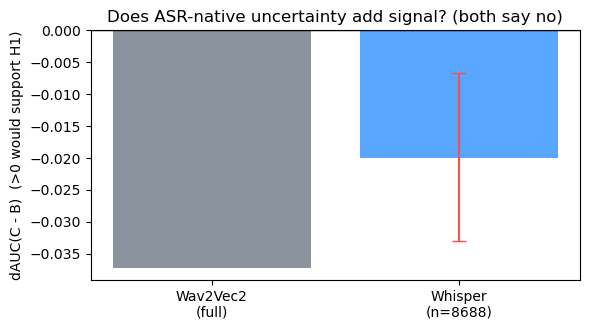

In [3]:
w2 = json.load(open(ROOT / "reports" / "phase6_voxintel_r_slurp" / "frozen_split_summary.json"))
w2B = w2["best_model"]["roc_auc"]; w2gap = w2["H1_asr_adds_beyond_intent"]["mean_gap_C_minus_B"]
tbl = pd.DataFrame([
    {"ASR front-end": "Wav2Vec2-CTC (full 8,688)", "B AUC": round(w2B, 3),
     "dAUC(C-B)": round(w2gap, 3), "H1": "NOT SUPPORTED"},
    {"ASR front-end": f"Whisper-base.en (n={len(df)})", "B AUC": round(aucB, 3),
     "dAUC(C-B)": round(gap["mean_gap"], 3), "H1": "SUPPORTED" if supported else "NOT SUPPORTED"},
])
print(tbl.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(["Wav2Vec2\n(full)", f"Whisper\n(n={len(df)})"], [w2gap, gap["mean_gap"]],
       color=["#8b949e", "#58a6ff"])
ax.errorbar([1], [gap["mean_gap"]], yerr=[[gap["mean_gap"] - gap["ci95_low"]],
            [gap["ci95_high"] - gap["mean_gap"]]], fmt="none", ecolor="#f85149", capsize=5)
ax.axhline(0, color="k", lw=1)
ax.set_ylabel("dAUC(C - B)  (>0 would support H1)")
ax.set_title("Does ASR-native uncertainty add signal? (both say no)")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "phase9_whisper_cross_asr" / "whisper_vs_wav2vec2_h1.png", dpi=140)
plt.show()

## Reading the result

- The number that matters is the **sign of ΔAUC(C−B)** and whether its CI crosses 0 —
  not the raw AUC magnitude, which differs because Whisper produces different
  transcripts and this is a seeded subset, not the full 8,688-clip corpus.
- If ΔAUC(C−B) is negative-or-zero with a CI that does not clear 0 (as for Wav2Vec2),
  the H1 negative **generalizes across ASR architectures**: intent-native uncertainty
  is a near-sufficient statistic for downstream failure regardless of whether the ASR
  is CTC or seq2seq. That is the strongest single answer to the "only one model pair"
  critique.
- If instead the CI clears 0 and ≥ 11/20 splits favour C, Whisper's richer internal-LM
  uncertainty **does** add signal CTC did not — a genuinely new finding worth the full
  run. Either way the evidence, not the prior, decides.
- **Next step for a full verdict:** `python src/analysis/whisper_asr_eval.py` (no
  `--limit`) decodes all 8,688 clips and rewrites `whisper_h1.json`; re-run this
  notebook on that cache.